# EDA: Big West Track & Field Data

Looks only at the data: regular-season marks and Big West championship results. 
Model checks (profiles, conversions, calibration, fold results) live in `model_checks.ipynb`.

`bigwest_model` is imported **only** to load and clean the files exactly the way the model does
(status codes, event names, dates, the `p` scale). No model functions are called.

**The p scale:** `p = log(mark)` for field and multi events, `−log(time)` for running events. Higher is always better,
and a difference of 0.01 is about 1%.

| # | Section | Question |
|---|---|---|
| 1 | Overview | Is the data complete and consistent across seasons and teams? |
| 2 | Coverage | Do Big West entrants have regular-season marks in their event? |
| 3 | Scoring | Is the points table the same every year? |
| 4 | Season comparability | Is 2019 (and every other season) on the same level? |
| 5 | Qualifiers vs non-qualifiers | How do entrants differ from athletes who didn't enter? |
| 6 | Season marks vs Big West | Which season summary is closest to the Big West mark? What does the gap look like? |
| 7 | Gap by ability | Do top and bottom athletes change by the same amount at Big West? |
| 8 | Event relationships | How closely are related events (60 → 100, Mile → 1500) linked? |
| 9 | Indoor vs outdoor | Are indoor marks comparable to outdoor marks? |
| 10 | Wind | Do wind-aided marks predict Big West as well as legal ones? |
| 11 | Failure | Does a season failure rate carry over to Big West? |
| 12 | Participation | Does every entrant start? |
| 13 | Cross-event correlation | Are an athlete's events at Big West linked (shared good or bad day)? |
| 14 | Relays | Do relays behave like individual events? |
| 15 | HJ / PV ties | How often are places tied in the vertical jumps? |
| 16 | Timing | How recent is each athlete's last mark before Big West? |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import bigwest_model as bm   
REG_PATH = "../data/processed/regular_season.csv"
BW_PATH = "../data/processed/bigwest_2019_2026_results.csv"


===== Fold: calibrate 2021-2022 -> test 2023 =====
conversions fitted: 20 | events skipped (no marks): none
day-form correlation used: 0.21 | blowups in training: 26
entrants using last season: 6 | entrants with no marks (imputed): 3
Brier (scores?)        model 0.111 | base 0.150
Team-event CRPS        model 1.24 | base 1.88   80% coverage 95%
M team totals          CRPS model 8.5 | MAE base 7.2   Spearman model 0.93 | base 0.97
W team totals          CRPS model 5.0 | MAE base 9.2   Spearman model 0.96 | base 0.88


,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
current,0.112,1.251,7.001,5.785,0.963,0.954


mark
NT    35
ND     6
Name: count, dtype: int64


## 0. Load data

In [ ]:
CFG = dict(bm.CONFIG)
reg = bm.load_regular(REG_PATH, CFG)
bw = bm.load_bigwest(BW_PATH, CFG)
seasons = sorted(int(s) for s in bw["season"].unique())
KEYS = ["gender", "event", "athlete_id"]

def event_group(e):
    if e in bm.RELAYS: return "relay"
    if e in bm.MULTIS: return "multi"
    if e in {"HJ", "PV"}: return "vertical jump"
    if e in {"LJ", "TJ"}: return "horizontal jump"
    if e in {"SP", "DT", "HT", "JT", "WT"}: return "throw"
    if e in {"55", "60", "100", "200", "300", "400", "60H", "100H", "110H", "300H", "400H"}: return "sprint/hurdle"
    return "distance"

def natural(p, event):
    """p back to natural units (meters, points or seconds)."""
    return np.exp(p) if bm.higher_is_better(event) else np.exp(-p)

reg["group"] = reg["event"].map(event_group)
bw["group"] = bw["event"].map(event_group)
bw_events = set(bw["event"])
valid = reg[reg["status"] == "VALID"].sort_values("date")

# One row per athlete, season and event: season best, mean, last 3, last mark, number of marks, last date
summ = (valid.groupby(["season"] + KEYS)
        .agg(best=("p", "max"), mean=("p", "mean"), last3=("p", lambda x: x.tail(3).mean()),
             last=("p", "last"), n=("p", "size"), last_date=("date", "max"))
        .reset_index())
summ["group"] = summ["event"].map(event_group)

# Big West entrants with a valid mark, joined to their season summary
bw_valid = bw[bw["status"] == "VALID"][["season", "group", "team", "place", "p"] + KEYS]
gap = bw_valid.merge(summ.drop(columns="group"), on=["season"] + KEYS)
print("Seasons:", seasons)
print(f"Regular season: {len(reg):,} rows, {reg['athlete_id'].nunique():,} athletes/relays")
print(f"Big West: {len(bw):,} entries | {len(gap):,} entries have a valid mark and a season summary")

Seasons: [2019, 2021, 2022, 2023, 2024, 2025, 2026]
Regular season: 57,300 rows, 2,746 athletes/relays
Big West: 5,257 entries | 4,782 entries have a valid mark and a season summary


## 1. Overview
**Question:** is the data complete and consistent across seasons and teams?

In [ ]:
print("Regular-season rows by season")
display(reg.groupby(["season", "gender"]).size().unstack(fill_value=0))
print("Big West entries by season")
display(bw.groupby(["season", "gender"]).size().unstack(fill_value=0))
print("Status counts")
display(pd.concat({"regular season": reg["status"].value_counts(),
                   "Big West": bw["status"].value_counts()}, axis=1).fillna(0).astype(int))

Regular-season rows by season


gender,M,W
season,,
2019,3106,3782
2021,2364,2449
2022,3858,4967
2023,3856,5331
2024,3823,5228
2025,3999,5674
2026,3657,5206


Big West entries by season


gender,M,W
season,,
2019,329,349
2021,311,331
2022,334,373
2023,356,383
2024,355,391
2025,426,466
2026,385,468


Status counts


,regular season,Big West
status,,
VALID,54926,5047
FAILED,2137,204
DID_NOT_COMPETE,192,6
MISSING,45,0


**Summary**
- 96% of marks are valid in both datasets, and the failure rate (DNF, DQ, foul-out, no height) is about 4% in both the regular season and at Big West. DNS entries are rare (0.3% and 0.1%), and only 45 marks (0.1%) could not be parsed.

## 2. Coverage
**Question:** do Big West entrants have regular-season marks in the event they enter?

coverage,marks in other events only,marks in this event,no marks at all,All
season,,,,
2019,44,600,2,646
2021,50,563,2,615
2022,33,640,0,673
2023,33,670,1,704
2024,35,673,2,710
2025,37,818,0,855
2026,51,761,0,812
All,283,4725,7,5015


coverage      marks in other events only  marks in this event  no marks at all
gender event                                                                  
M      10000                        0.68                 0.31             0.01
W      10000                        0.55                 0.44             0.01
M      Dec                          0.24                 0.76             0.00
W      Hep                          0.22                 0.78             0.00
       5000                         0.13                 0.86             0.00
M      5000                         0.12                 0.88             0.00
       TJ                           0.04                 0.96             0.00
       JT                           0.03                 0.97             0.00
       3000S                        0.03                 0.97             0.00
W      400                          0.02                 0.98             0.00
       400H                         0.02                 0.98             0.00
M      110H                         0.02                 0.98             0.00
W      JT                           0.02                 0.98             0.00
       TJ                           0.02                 0.98             0.00
M      LJ                           0.01                 0.99             0.00

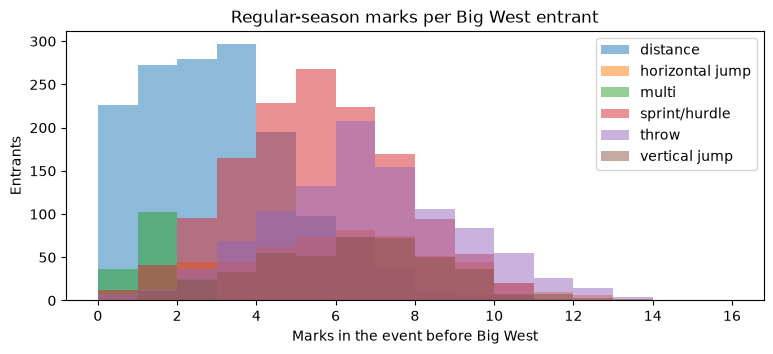

In [ ]:
ent = bw[~bw["event"].isin(bm.RELAYS)][["season", "group"] + KEYS].drop_duplicates()
ent = ent.merge(summ[["season"] + KEYS + ["n"]], on=["season"] + KEYS, how="left").fillna({"n": 0})
ent["has_marks"] = ent["n"] > 0
any_marks = set(zip(reg["season"], reg["athlete_id"]))
ent["any_event"] = [(s, a) in any_marks for s, a in zip(ent["season"], ent["athlete_id"])]
ent["coverage"] = np.select([ent["has_marks"], ent["any_event"]],
                            ["marks in this event", "marks in other events only"], "no marks at all")

display(pd.crosstab(ent["season"], ent["coverage"], margins=True))
tab = pd.crosstab([ent["gender"], ent["event"]], ent["coverage"], normalize="index").round(2)
display(tab.sort_values("marks in this event").head(15))

fig, ax = plt.subplots(figsize=(9, 3.5))
for g, grp in ent.groupby("group"):
    ax.hist(grp["n"].clip(upper=15), bins=range(0, 17), alpha=0.5, label=g)
ax.set_xlabel("Marks in the event before Big West"); ax.set_ylabel("Entrants"); ax.legend()
ax.set_title("Regular-season marks per Big West entrant"); plt.show()

**Summary**
- 94% of entrants have marks in the event they are entered in at the Championship meet. 6% have marks only in other events, and just 7 have no marks at all
- Only 31% of men and 44% of women in the 10000 ran one during the regular season, because athletes race it rarely. Their predictions depend on converting from the 5000
- About 23% of decathletes and heptathletes had no multi score that season, so they rely on indoor multis or last season’s score


## 3. Scoring table
**Question:** is the place-to-points table the same every year, and are ties rare?

In [ ]:
b = bw[bw["points"] > 0].copy()
b["place_n"] = pd.to_numeric(b["place"], errors="coerce")
b["kind"] = np.where(b["event"].isin(bm.RELAYS), "relay", "individual")
display(b.pivot_table(index=["kind", "season"], columns="place_n", values="points",
                      aggfunc=lambda x: x.mode().iloc[0]))

tot = bw.groupby(["season", "gender", "event"])["points"].sum()
print("Events where total points != 39 (10+8+6+5+4+3+2+1):")
display(tot[tot.round(1) != 39].reset_index())

place_n             1.0  2.0  3.0  4.0  5.0  6.0  7.0  8.0
kind       season                                         
individual 2019    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2021    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2022    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2023    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2024    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2025    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2026    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
relay      2019    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2021    10.0  8.0  6.0  5.0  4.0  3.0  2.0  NaN
           2022    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2023    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2024    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2025    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2026    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0

Events where total points != 39 (10+8+6+5+4+3+2+1):


,season,gender,event,points
0,2019,M,400H,38.0
1,2019,M,4x100,38.0
2,2019,W,4x100,36.0
3,2021,M,110H,38.0
4,2021,M,200,38.0
5,2021,M,400,38.0
6,2021,M,4x100,38.0
7,2021,M,4x400,38.0
8,2021,W,4x100,38.0
9,2021,W,4x400,36.0


**Summary**
- Totals other than 39 mean tied places (points split) means that someone in the sprint events DNS,DQ,or DNF in the finals

## 4. Season comparability
**Question:** is every season, especially 2019, on the same level? Compares the median season best of all athletes
per event and season, as a % difference from that event's median over all seasons (+ = better than usual).

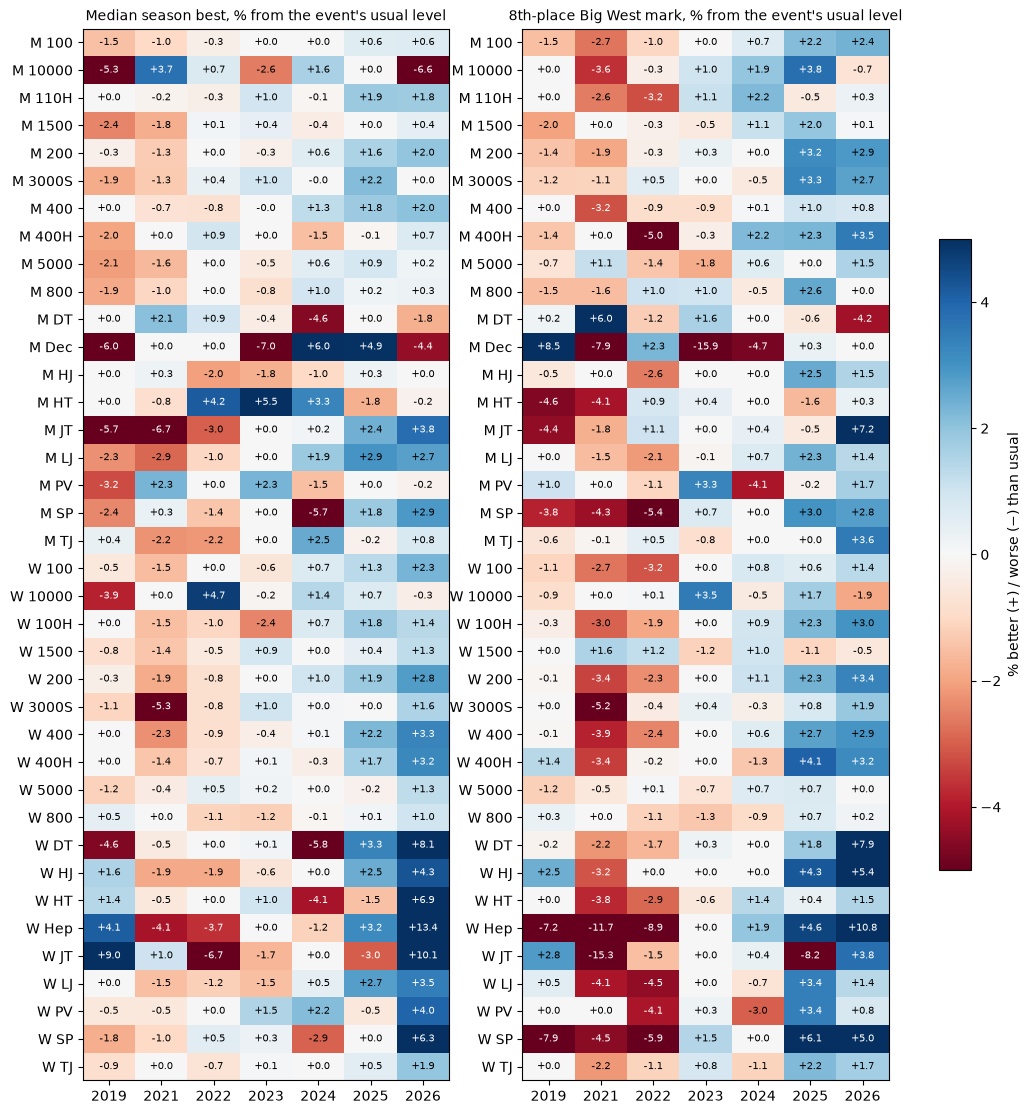

In [ ]:
bw_pairs = pd.MultiIndex.from_frame(bw[["gender", "event"]].drop_duplicates())
in_bw = pd.MultiIndex.from_frame(summ[["gender", "event"]]).isin(bw_pairs)
ind_s = summ[~summ["event"].isin(bm.RELAYS) & in_bw]
med = ind_s.groupby(["gender", "event", "season"])["best"].median().unstack("season")
diff = 100 * med.sub(med.median(axis=1), axis=0)

top8 = (bw_valid[~bw_valid["event"].isin(bm.RELAYS)]
        .sort_values("p", ascending=False).groupby(["season", "gender", "event"]).nth(7))
t8 = top8.set_index(["gender", "event", "season"])["p"].unstack("season")
diff8 = 100 * t8.sub(t8.median(axis=1), axis=0)

def heatmap(ax, d, title, lim=5):
    """Diverging heatmap: blue = better than usual, red = worse, gray = no data."""
    cmap = plt.get_cmap("RdBu").copy()
    cmap.set_bad("lightgray")
    im = ax.imshow(np.ma.masked_invalid(d.to_numpy(dtype=float)), cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(d.shape[1]), d.columns)
    ax.set_yticks(range(d.shape[0]), [f"{g} {e}" for g, e in d.index])
    ax.set_title(title, fontsize=10)
    for i in range(d.shape[0]):
        for j in range(d.shape[1]):
            val = d.iat[i, j]
            if pd.notna(val):
                ax.text(j, i, f"{val:+.1f}", ha="center", va="center", fontsize=7,
                        color="white" if abs(val) > 0.6 * lim else "black")
    return im

fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(diff) + 1.5), sharey=False)
heatmap(axes[0], diff, "Median season best, % from the event's usual level")
im = heatmap(axes[1], diff8.reindex(diff.index), "8th-place Big West mark, % from the event's usual level")
fig.colorbar(im, ax=axes, shrink=0.6, label="% better (+) / worse (−) than usual")
plt.show()

**Summary**
The conference has gotten better over time. Most cells are red (worse than usual) in 2019–2022 and blue (better) in 2025–2026, and both panels show it. The left panel is the median season best of everyone who competed; the right panel is the 8th-place mark at Big West, the level needed to score. So the whole field improved, and so did the bar to score.

## 5. Qualifiers vs non-qualifiers
**Question:** how do Big West entrants compare to athletes who competed in the event but didn't enter it?

In [ ]:
s5 = ind_s.copy()
entered = set(zip(ent["season"], ent["gender"], ent["event"], ent["athlete_id"]))
s5["entered"] = [k in entered for k in zip(s5["season"], s5["gender"], s5["event"], s5["athlete_id"])]
s5["pct_rank"] = s5.groupby(["season", "gender", "event"])["best"].rank(pct=True)   # 1 = best in the event
display(s5.groupby(["group", "entered"])["pct_rank"].describe()[["count", "25%", "50%", "75%"]].round(2))

# Non-entrants whose season best would have placed in the top 8 at Big West that year
eligible = ~((s5["team"] == "UC SAN DIEGO") & s5["season"].between(2021, 2024)) if "team" in s5 else True
eighth_sb = (s5[s5["entered"]].sort_values("best", ascending=False)
             .groupby(["season", "gender", "event"]).nth(7)
             [["season", "gender", "event", "best"]]
             .rename(columns={"best": "eighth_sb"}))
s5b = s5.merge(eighth_sb, on=["season", "gender", "event"], how="left")

ucsd_ids = set(reg.loc[reg["team"] == "UC SAN DIEGO", "athlete_id"])
ineligible = s5b["athlete_id"].isin(ucsd_ids) & s5b["season"].between(2021, 2024)
missed = s5b[~s5b["entered"] & (s5b["best"] >= s5b["eighth_sb"]) & ~ineligible]

print(len(missed), "eligible non-entrants with a season best in the entrants' top 8")
display(missed.groupby(["season", "gender"]).size().unstack(fill_value=0))

count   25%   50%   75%
group           entered                          
distance        False    2676.0  0.19  0.38  0.60
                True     1274.0  0.60  0.79  0.90
horizontal jump False     553.0  0.15  0.30  0.50
                True      524.0  0.54  0.72  0.88
multi           False      31.0  0.13  0.25  0.42
                True      127.0  0.39  0.60  0.81
sprint/hurdle   False    2719.0  0.18  0.35  0.57
                True     1364.0  0.64  0.79  0.91
throw           False    1010.0  0.14  0.28  0.43
                True     1009.0  0.59  0.75  0.88
vertical jump   False     397.0  0.15  0.28  0.45
                True      427.0  0.56  0.72  0.86

275 eligible non-entrants with a season best in the entrants' top 8


gender,M,W
season,,
2019,15,17
2021,17,24
2022,29,22
2023,25,24
2024,17,19
2025,9,19
2026,16,22


**Summary**
-Each year, about 30–50 eligible athletes (9–29 per gender) were not entered in an event even though their season best ranked in the entrants’ top 8. That’s roughly one per event per gender, and it stays steady across seasons. So teams regularly leave capable athletes out of events, and projecting entries by season best alone would overrate deep teams.probably because of some type of injury or saturation of athletes in an event(don't want a single athlete to be in 4+ events ) 

## 6. Season marks vs Big West
**Question:** which season summary is closest to the Big West mark, and what does the gap look like?
`gap = Big West p − summary p` (+ = better at Big West, 0.01 ≈ 1%).

In [ ]:
ind_g = gap[~gap["event"].isin(bm.RELAYS)].copy()
out = {}
for c in ["best", "mean", "last3", "last"]:
    err = ind_g["p"] - ind_g[c]
    err_bc = err - err.groupby([ind_g["gender"], ind_g["event"]]).transform("mean")
    out[c] = {"bias %": 100 * err.mean(), "MAE %": 100 * err.abs().mean(),
              "bias-corrected MAE %": 100 * err_bc.abs().mean()}
display(pd.DataFrame(out).T.round(3).sort_values("bias-corrected MAE %"))

,bias %,MAE %,bias-corrected MAE %
mean,0.778,2.805,2.503
best,-1.728,2.865,2.505
last3,0.394,2.694,2.526
last,0.058,2.954,2.831


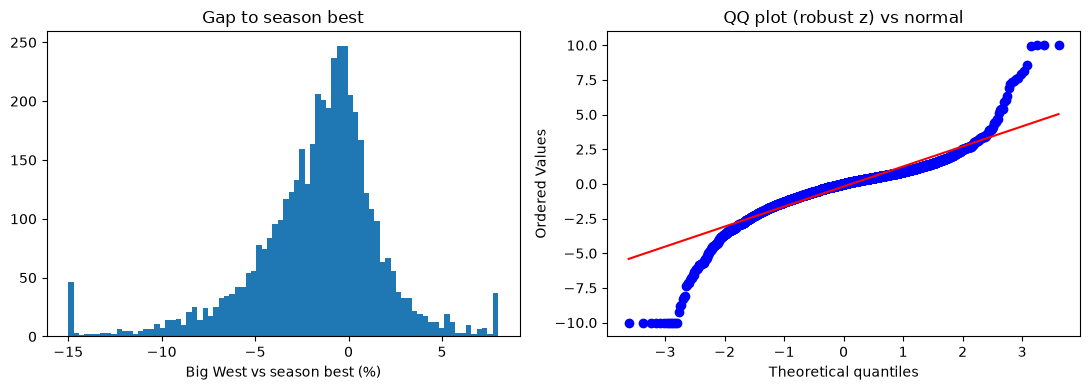

Share of entrants who beat their season best at Big West: 28.8%
skew: -7.17   excess kurtosis: 132.69   share beyond 4 robust sd below: 1.8%


,mean,std,min,5%,25%,50%,75%,max,n
group,,,,,,,,,
distance,-1.99,2.63,-16.57,-6.43,-3.47,-1.65,-0.30,7.22,1246
horizontal jump,-1.83,3.47,-18.40,-7.09,-3.87,-1.60,0.22,12.21,491
multi,3.50,8.71,-32.03,-6.57,-0.11,2.18,5.22,46.56,126
sprint/hurdle,-0.94,5.30,-110.31,-3.40,-1.48,-0.47,0.42,4.57,1330
throw,-2.93,6.70,-104.57,-12.05,-5.57,-2.47,0.59,13.99,968
vertical jump,-2.12,2.89,-10.48,-7.56,-3.90,-2.02,-0.14,6.35,392


In [ ]:
ind_g["gap_sb"] = ind_g["p"] - ind_g["best"]
z = (ind_g["gap_sb"] - ind_g["gap_sb"].median()) / stats.median_abs_deviation(ind_g["gap_sb"], scale="normal")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(100 * ind_g["gap_sb"].clip(-0.15, 0.08), bins=80)
ax[0].set_xlabel("Big West vs season best (%)"); ax[0].set_title("Gap to season best")
stats.probplot(z.clip(-10, 10), plot=ax[1]); ax[1].set_title("QQ plot (robust z) vs normal")
plt.tight_layout(); plt.show()

print(f"Share of entrants who beat their season best at Big West: {(ind_g['gap_sb'] > 0).mean():.1%}")
print(f"skew: {stats.skew(z):.2f}   excess kurtosis: {stats.kurtosis(z):.2f}   "
      f"share beyond 4 robust sd below: {(z < -4).mean():.1%}")
display((100 * ind_g.groupby("group")["gap_sb"].describe(percentiles=[0.05, 0.25, 0.5, 0.75]))
        .drop(columns="count").round(2).assign(n=ind_g.groupby("group").size()))

**Summary**
- Season best overstates championship form. Athletes average 1.7% below their season best at Big West, and only about 29% beat it

- Some summaries are consistently too high or too low. Athletes usually finish about 1.7% below their season best at Big West, and about 0.8% above their season average. Once each summary is adjusted by that typical amount, the season average and season best predict equally well (both off by 2.50% on average). The average of the last 3 marks is close behind (2.53%), and the single most recent mark is the least accurate (2.83%).

- A typical athlete finishes 1.5–2.5% below their season best,sprint/hurles are the most predictable,throws are the least, multis season summary underestimates them

## 7. Gap by ability
**Question:** do top and bottom athletes in a field change by the same amount at Big West?

In [ ]:
ind_g["field_rank"] = ind_g.groupby(["season", "gender", "event"])["best"].rank(pct=True, ascending=False)
ind_g["ability"] = pd.cut(ind_g["field_rank"], [0, 0.25, 0.5, 0.75, 1.0],
                          labels=["top 25%", "25-50%", "50-75%", "bottom 25%"])
display(ind_g.groupby("ability", observed=True)["gap_sb"]
        .agg(median_pct=lambda x: 100 * x.median(), mean_pct=lambda x: 100 * x.mean(), n="size").round(2))
display((100 * ind_g.pivot_table(index="group", columns="season", values="gap_sb", aggfunc="median")).round(2))

,median_pct,mean_pct,n
ability,,,
top 25%,-1.09,-2.13,1033
25-50%,-1.26,-1.84,1172
50-75%,-1.37,-1.93,1112
bottom 25%,-0.91,-1.11,1236


season,2019,2021,2022,2023,2024,2025,2026
group,,,,,,,
distance,-0.98,-0.48,-2.24,-1.93,-1.67,-1.81,-2.41
horizontal jump,-0.57,-1.11,-1.49,-1.37,-1.66,-2.07,-2.05
multi,1.38,5.30,0.84,4.00,0.13,1.29,2.22
sprint/hurdle,-0.47,-0.59,-0.93,-0.55,-0.53,-0.28,-0.16
throw,-2.11,-1.65,-4.01,-1.28,-3.08,-2.89,-2.52
vertical jump,-1.53,-2.12,-2.45,-2.45,-1.50,-1.82,-2.33


**What to look for**
- If the bottom of the field gains more (or loses less) than the top, part of that is regression to the mean:
  athletes who barely made the field often had a lucky season best.
- A season where every group moves together points to conditions that year (weather, venue).

## 8. Event relationships
**Question:** how closely are related events linked? Each point is one athlete-season with season bests in both events.

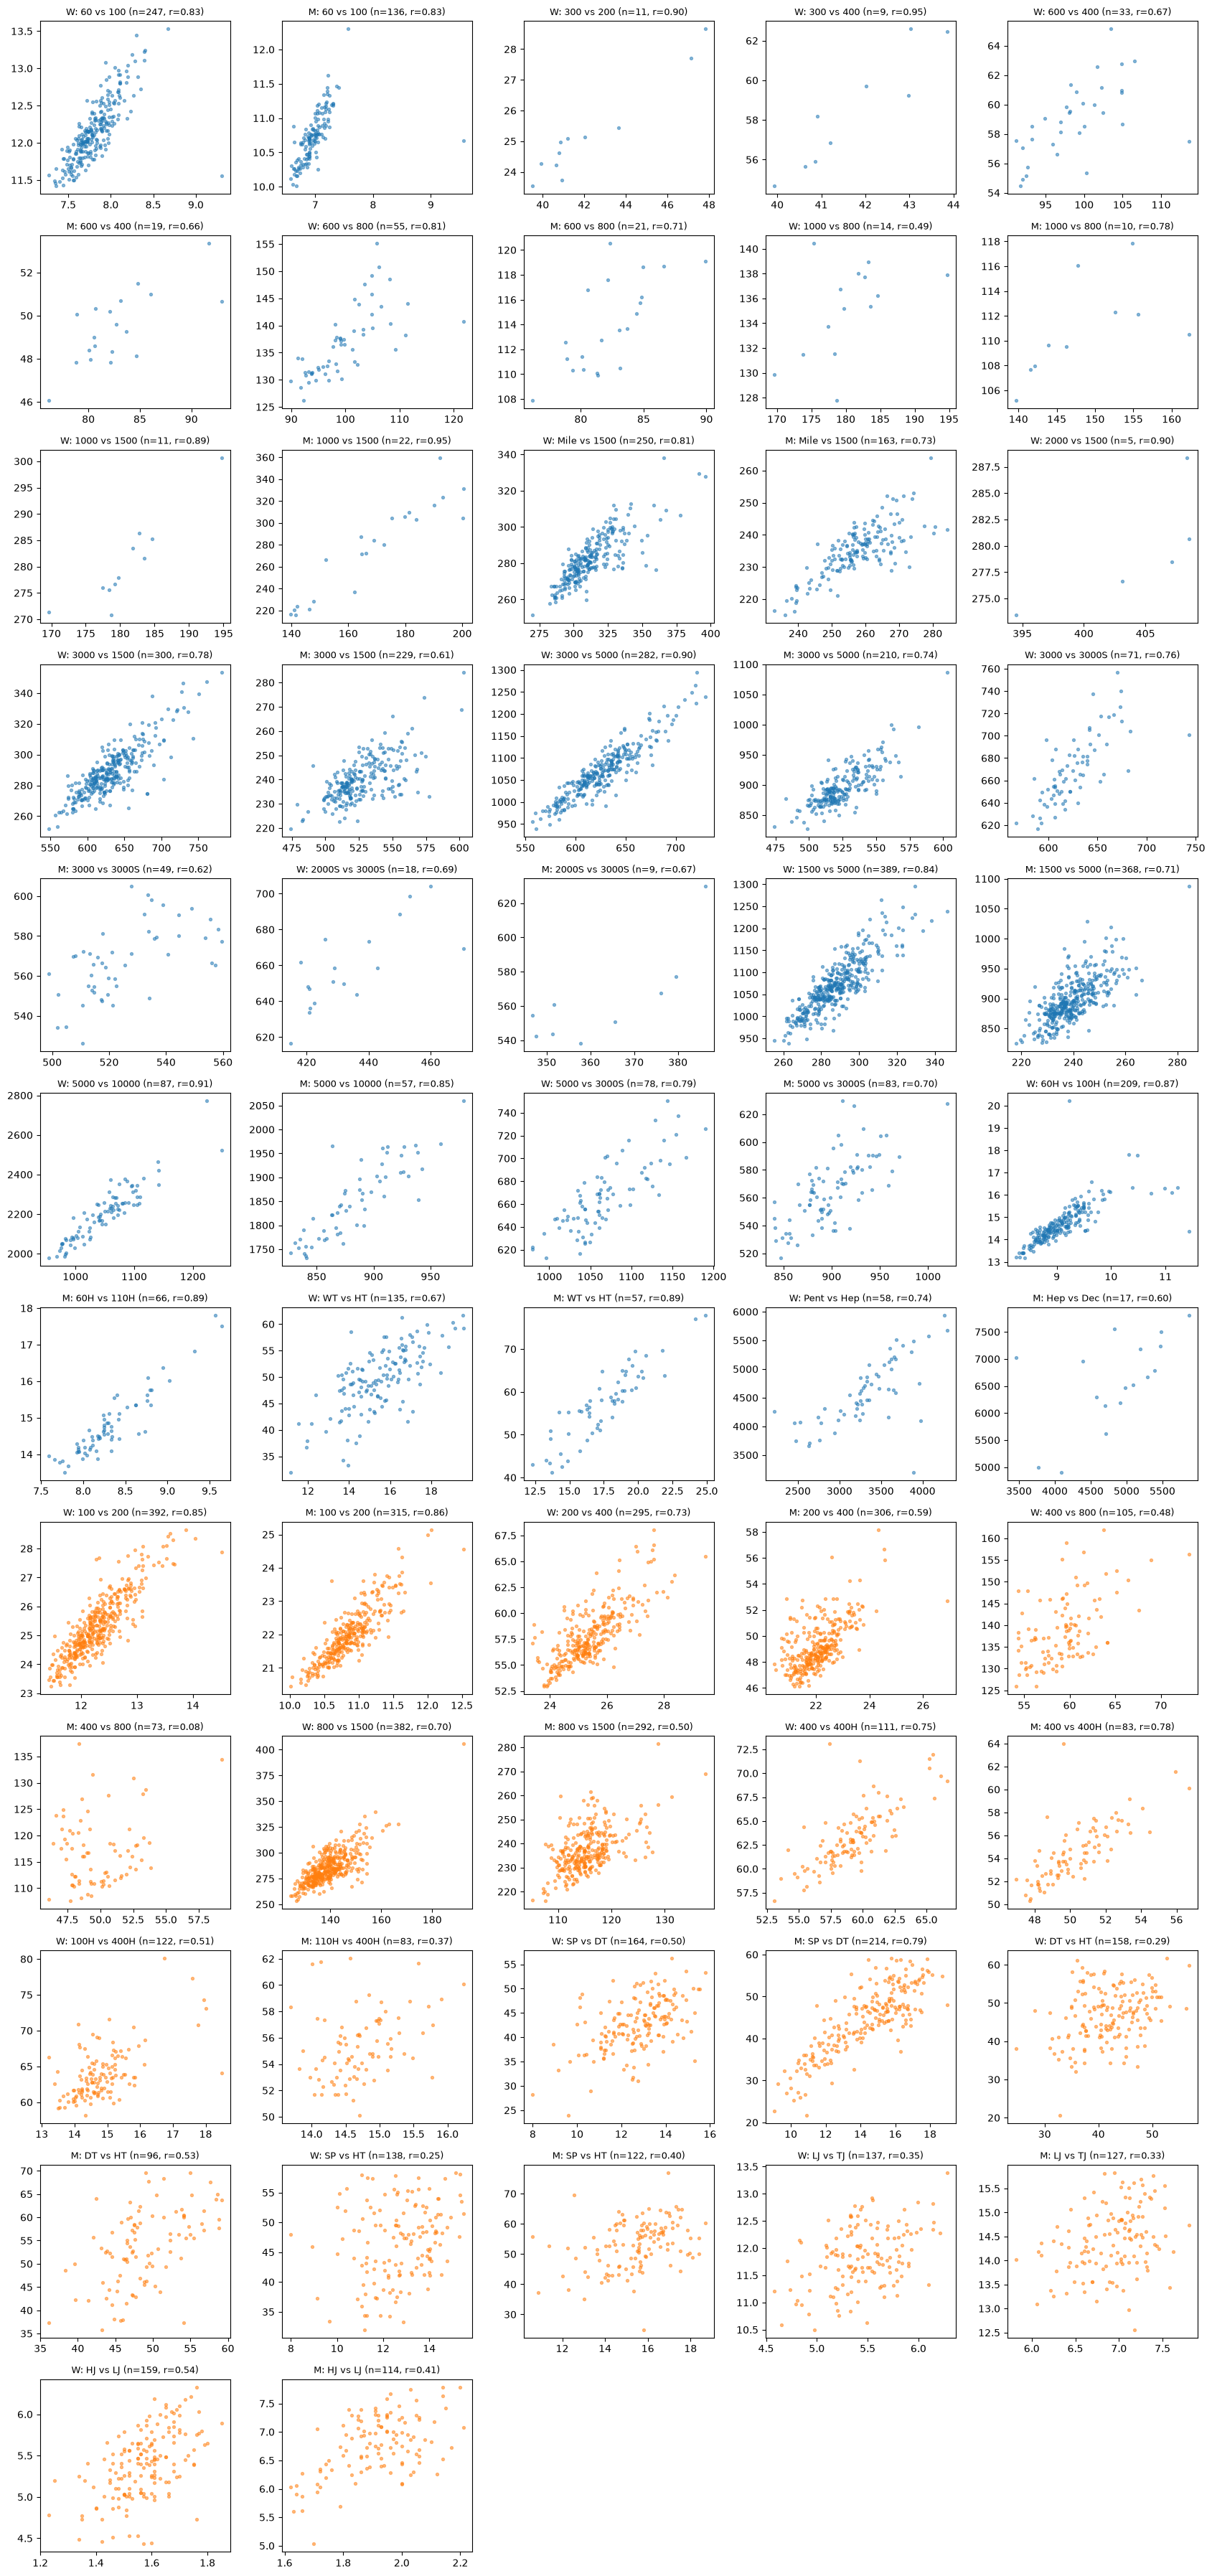

,gender,source,target,used_in_model,n,spearman
8,W,1000,800,True,14,0.49
34,M,Hep,Dec,True,17,0.60
16,M,3000,1500,True,229,0.61
20,M,3000,3000S,True,49,0.62
5,M,600,400,True,19,0.66
4,W,600,400,True,33,0.67
22,M,2000S,3000S,True,9,0.67
31,W,WT,HT,True,135,0.67
21,W,2000S,3000S,True,18,0.69
28,M,5000,3000S,True,83,0.70


In [ ]:
sb = valid.groupby(["season", "gender", "athlete_id", "event"])["p"].max().unstack("event")

# Pairs the model already converts (CONVERT / CROSS / 60H / multis)
model_pairs = [("60", "100"), ("300", "200"), ("300", "400"), ("500", "400"), ("600", "400"), ("600", "800"),
               ("1000", "800"), ("1000", "1500"), ("Mile", "1500"), ("2000", "1500"),
               ("3000", "1500"), ("3000", "5000"), ("3000", "3000S"), ("2Mile", "5000"), ("2000S", "3000S"),
               ("1500", "5000"), ("5000", "10000"), ("5000", "3000S"),
               ("60H", "100H"), ("60H", "110H"), ("300H", "400H"), ("WT", "HT"), ("Pent", "Hep"), ("Hep", "Dec")]
# Plausibly related pairs the model does NOT convert
other_pairs = [("100", "200"), ("200", "400"), ("400", "800"), ("800", "1500"), ("400", "400H"),
               ("100H", "400H"), ("110H", "400H"), ("SP", "DT"), ("DT", "HT"), ("SP", "HT"),
               ("LJ", "TJ"), ("HJ", "LJ")]

def valid_pair(g, a, b_):
    if g == "W" and (b_ in {"110H", "Dec"} or a == "110H"): return False     # men-only events
    if g == "M" and (b_ == "100H" or a in {"100H", "Pent"}): return False    # women-only / not held
    if g == "W" and a == "Hep" and b_ == "Dec": return False
    return True

pairs = [(g, a, b_, kind) for kind, lst in [("model", model_pairs), ("other", other_pairs)]
         for a, b_ in lst for g in ["W", "M"] if valid_pair(g, a, b_)]
shown = [(g, a, b_, k) for g, a, b_, k in pairs if {a, b_} <= set(sb.columns)
         and len(sb.xs(g, level="gender")[[a, b_]].dropna()) >= 5]

ncols = 5
nrows = int(np.ceil(len(shown) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 3 * nrows), squeeze=False)
rows = []
for ax, (g, a, b_, k) in zip(axes.flat, shown):
    both = sb.xs(g, level="gender")[[a, b_]].dropna()
    r = stats.spearmanr(both[a], both[b_])[0]
    rows.append(dict(gender=g, source=a, target=b_, used_in_model=(k == "model"), n=len(both), spearman=round(r, 2)))
    ax.scatter(natural(both[a], a), natural(both[b_], b_), s=8, alpha=0.5, color="C0" if k == "model" else "C1")
    ax.set_title(f"{g}: {a} vs {b_} (n={len(both)}, r={r:.2f})", fontsize=9)
for ax in list(axes.flat)[len(shown):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

display(pd.DataFrame(rows).sort_values(["used_in_model", "spearman"], ascending=[False, True]))

**Summary**
- **Storngly Corellated events:** (60 → 100),(60H → 100H / 110H),(Mile → 1500),(1500 → 5000),(W 3000 → W 5000), (5000 → 10000), (W 5000 → 3000S), (W 600 → 800),(M WT → HT),(100 ↔ 200),400 ↔ 400H,M SP ↔ DT
- **Moderate**: M 3000 → 1500, M 3000 → 3000S, 600 → 400,W WT → HT
- **Weakly Correlated Events**: 400 ↔ 800,100H/110H → 400H, 800 → 1500,DT ↔ HT,SP ↔ HT,LJ ↔ TJ,HJ ↔ LJ, 
- **Thin corrleation data**: M Hep → Dec,300 → 200/400,1000 → 800/1500,2000 → 150


## 9. Indoor vs outdoor
**Question:** are indoor marks comparable to outdoor marks in the same event? There's no indoor flag, so
January–February stands in for indoor. Part of any gap is later-season fitness, not the venue.

In [ ]:
v9 = valid.copy()

# MPSF Indoor end date per season (the end of indoor for almost everyone)
mpsf = v9[v9["meet_name"].str.contains(r"MPSF", case=False, na=False)].groupby("season")["date"].max()
v9["mpsf_date"] = v9["season"].map(mpsf)              # NaT for 2021: no indoor season
name = v9["meet_name"].fillna("")
month = v9["date"].dt.month

named_indoor = (name.str.contains(r"indoor|NCAA Division I Indoor|Arkansas Qualifier", case=False)
                | (name.str.contains(r"last chance", case=False) & month.between(1, 3)))
named_outdoor = name.str.contains(r"sunbird|rossi relays", case=False)

v9["venue"] = np.where(named_indoor | ((v9["date"] <= v9["mpsf_date"]) & ~named_outdoor),
                       "indoor", "outdoor")

print("MPSF cutoff by season:", {int(s): str(d.date()) for s, d in mpsf.items()})
print(pd.crosstab(v9["season"], v9["venue"]))

# Same comparison as before
evs = ["200", "400", "800", "SP", "LJ", "TJ", "HJ", "PV"]
sbv = (v9[v9["event"].isin(evs)].groupby(["season", "gender", "athlete_id", "event", "venue"])["p"].max()
       .unstack("venue").dropna())
sbv["outdoor_better_pct"] = 100 * (sbv["outdoor"] - sbv["indoor"])
display(sbv.groupby("event")["outdoor_better_pct"].agg(["median", "mean", "size"]).round(2))

MPSF cutoff by season: {2019: '2019-02-23', 2022: '2022-02-19', 2023: '2023-02-18', 2024: '2024-02-26', 2025: '2025-02-22', 2026: '2026-03-02'}
venue   indoor  outdoor
season                 
2019      1303     5312
2021         0     4628
2022      1359     7147
2023      1952     6872
2024      2058     6535
2025      1973     7323
2026      1879     6585


,median,mean,size
event,,,
200,1.38,1.52,491
400,1.32,1.48,276
800,2.39,2.87,237
HJ,0.62,0.79,233
LJ,3.19,3.46,340
PV,2.67,2.62,135
SP,2.84,3.09,295
TJ,1.68,1.93,169


**Summary**
- Outdoor season bests are 1–3% better than indoor ones in every event. The sprint gap (about 1.4%) is no bigger than the gap in field events, where the venue doesn’t matter. So the difference comes from athletes improving through the season, not from indoor tracks being slower. Indoor marks can be used as points for the model

## 10. Wind
**Question:** do wind-aided marks (tailwind over 2.0 m/s) predict Big West as well as legal ones?

In [ ]:
wv = valid[valid["event"].isin(bm.WIND_EVENTS)].copy()
wv["wind"] = pd.to_numeric(wv["wind"], errors="coerce")
wv["aided"] = wv["wind"] > 2.0
print("Share of marks wind-aided, by event:")
display(wv.groupby("event")["aided"].mean().round(3))

g10 = wv.groupby(["season"] + KEYS)
w_cmp = pd.DataFrame({"all_marks": g10["p"].mean(),
                      "legal_only": wv[~wv["aided"]].groupby(["season"] + KEYS)["p"].mean()}).dropna()
w_cmp = w_cmp.reset_index().merge(bw_valid[["season"] + KEYS + ["p"]], on=["season"] + KEYS)
for c in ["all_marks", "legal_only"]:
    e = w_cmp["p"] - w_cmp[c]
    e = e - e.groupby(w_cmp["event"]).transform("mean")
    print(f"{c:>11}: bias-corrected MAE {100 * e.abs().mean():.3f}%   (n={len(e)})")

Share of marks wind-aided, by event:


event
100     0.136
100H    0.135
110H    0.141
200     0.098
LJ      0.081
TJ      0.085
Name: aided, dtype: float64

  all_marks: bias-corrected MAE 1.897%   (n=1351)
 legal_only: bias-corrected MAE 1.927%   (n=1351)


**Summary**
- tailwind makes a mark only about 1–2% faster, and an aided mark is one of several marks averaged together for each athlete
- About 28% of marks are in wind-affected events, and most of those (84%) have a wind reading. Of the marks with a reading, about 13% (1,614) were wind-aided (tailwind > 2.0 m/s), which is about 3% of all marks.
- Does not hurt model if we chose to keep wind aided marks

## 11. Failure
**Question:** does an athlete's season failure rate (foul out, DNF, DQ, no height) carry over to Big West?

In [ ]:
dm = reg[reg["status"].isin(["VALID", "FAILED"]) & ~reg["event"].isin(bm.RELAYS)]
fr = (dm.assign(f=dm["status"].eq("FAILED")).groupby(["season"] + KEYS)["f"]
      .agg(season_fail_rate="mean", n_entries="size").reset_index())
bwf = bw[bw["status"].isin(["VALID", "FAILED"]) & ~bw["event"].isin(bm.RELAYS)][["season", "group"] + KEYS + ["status"]]
bwf["champ_failed"] = bwf["status"].eq("FAILED")
ff = bwf.merge(fr, on=["season"] + KEYS, how="left")
ff["season_bin"] = pd.cut(ff["season_fail_rate"].fillna(-1), [-1.5, -0.5, 0, 0.2, 1.0],
                          labels=["no history", "0%", "0-20%", ">20%"])
display(ff.groupby("season_bin", observed=True)["champ_failed"].agg(["mean", "size"]).round(3))

print("Failure rate by group: season vs Big West")
display(pd.DataFrame({"season": dm.assign(f=dm["status"].eq("FAILED")).groupby("group")["f"].mean(),
                      "Big West": ff.groupby("group")["champ_failed"].mean()}).round(3))

,mean,size
season_bin,,
no history,0.086,280
0%,0.025,4077
0-20%,0.085,386
>20%,0.120,266


Failure rate by group: season vs Big West


,season,Big West
group,,
distance,0.030,0.033
horizontal jump,0.052,0.064
multi,0.013,0.012
sprint/hurdle,0.009,0.022
throw,0.040,0.041
vertical jump,0.118,0.082


**Summary**
- An athlete’s season failure rate predicts failure at Big West,The more often an athlete failed during the season (DNF, DQ, fouling out, no height), the more likely they were to fail at Big West
- No history means the athlete had no regular-season entries in that event, for example someone stepping up from the 5000 to the 10000. They fail about as often as the 0–20% group, so an untested event carries extra risk.
- Failure rates are approximately the same in distance and throws events, it is greater in sprint/hurldes and horizontal jumps, and lower in vertical jumps


## 12. Participation
**Question:** does every entrant start their event?

In [ ]:
display(pd.crosstab(bw["season"], bw["status"]))
dns = bw[bw["status"] == "DID_NOT_COMPETE"]
print(f"DNS / scratches: {len(dns)} of {len(bw)} entries ({100 * len(dns) / max(len(bw), 1):.1f}%)")
display(dns.groupby("group").size())

status,DID_NOT_COMPETE,FAILED,VALID
season,,,
2019,0,27,651
2021,1,16,625
2022,1,36,670
2023,0,17,722
2024,0,27,719
2025,1,43,848
2026,3,38,812


DNS / scratches: 6 of 5257 entries (0.1%)


group
sprint/hurdle    6
dtype: int64

**Summary**
- Only 6 of 5,257 Big West entries are recorded as DNS. This reflects the championship rule rather than missing data: an athlete who records a DNS is removed from all remaining events, including relays, so athletes either scratch before declarations close or start and drop out. As a result, the entrants in the results closely match the declared field known before the meet, so using them to build the simulated fields involves little leakage. Between 2% and 5% of entries each year start but record no mark (DNF, DQ, foul-out, no height); some of these, especially in sprints and hurdles, are likely injured athletes starting to stay eligible for later events.

## 13. Cross-event correlation
**Question:** when an athlete does 2+ individual events at the same Big West, are their gaps to season best linked?

In [ ]:
multi = ind_g.groupby(["season", "athlete_id"]).filter(lambda x: len(x) >= 2)
pz = []
for _, grp in multi.groupby(["season", "athlete_id"]):
    x = grp["gap_sb"].to_numpy()
    pz += [(x[i], x[j]) for i in range(len(x)) for j in range(i + 1, len(x))]
pz = np.array(pz)
if len(pz) > 2:
    print(f"Spearman r = {stats.spearmanr(pz[:, 0], pz[:, 1])[0]:.3f}   "
          f"Pearson r = {stats.pearsonr(pz[:, 0], pz[:, 1])[0]:.3f}   ({len(pz)} pairs)")
n_ev = ind_g.groupby(["season", "athlete_id"])["event"].transform("size")
display((100 * ind_g.groupby(np.where(n_ev >= 2, "2+ events", "1 event"))["gap_sb"].agg(["median", "mean"]))
        .round(2).assign(n=ind_g.groupby(np.where(n_ev >= 2, "2+ events", "1 event")).size()))

Spearman r = 0.124   Pearson r = 0.137   (1650 pairs)


,median,mean,n
1 event,-1.32,-1.91,1936
2+ events,-1.02,-1.59,2617


**Summary**
- An athlete's results across events at the same Big West are only weakly linked (Spearman r ≈ 0.12), so good and bad days carry over slightly between events. Athletes entered in two or more events finish no worse relative to their season best than single-event athletes, so there is no sign of a fatigue penalty from doubling; the small difference likely reflects that stronger athletes and sprinters are the ones who double

## 14. Relays
**Question:** do relays behave like individual events (season marks predict Big West equally well)?

In [ ]:
g14 = gap.copy()
g14["gap_sb"] = g14["p"] - g14["best"]
g14["kind"] = np.where(g14["event"].isin(bm.RELAYS), "relay", "individual")
g14 = g14[g14["group"].isin(["relay", "sprint/hurdle"])]
display((100 * g14.groupby(["kind", "event"])["gap_sb"].agg(["median", "std"])).round(2)
        .assign(n=g14.groupby(["kind", "event"]).size()))

median   std    n
kind       event                   
individual 100     -0.29  8.48  334
           100H    -0.07  2.28  123
           110H    -0.51  3.22   96
           200     -0.54  3.65  314
           400     -0.89  4.77  279
           400H    -0.30  2.50  184
relay      4x100   -0.36  1.09  107
           4x400   -0.15  1.45  122

**Summary**
- Relays are the most predictable events. Their gap to season best has the smallest spread: a standard deviation of 1.1% for the 4x100 and 1.5% for the 4x400, against 2.3–8.5% for the individual events. Their medians are close to zero (−0.4% and −0.2%), so teams run about as fast as their season best.
- The individual spreads are inflated by a few outliers blowups. The 100’s standard deviation of 8.5% comes from pull-ups like the 23.99. The medians show typical individual results are also close to season best: −0.1% to −0.9%, with the 400 lowest.

## 15. High jump and pole vault ties
**Question:** how often do HJ/PV athletes share a mark or a place?

In [ ]:
vj = bw[bw["event"].isin(["HJ", "PV"]) & (bw["status"] == "VALID")].copy()
vj["place_n"] = pd.to_numeric(vj["place"], errors="coerce")
tm = vj.groupby(["season", "gender", "event", "value"]).size()
tp = vj.groupby(["season", "gender", "event", "place_n"]).size()
print(f"HJ/PV athletes sharing their exact mark with another: {tm[tm > 1].sum() / max(len(vj), 1):.1%}")
print(f"HJ/PV athletes in a tied place: {tp[tp > 1].sum() / max(len(vj), 1):.1%}")

HJ/PV athletes sharing their exact mark with another: 80.9%
HJ/PV athletes in a tied place: 34.9%


**Summary**
- Most HJ/PV athletes clear the same heights. 81% finish on exactly the same height as at least one other athlete, because the bar goes up in fixed steps
- Countback breaks only some of those ties. Ties are first broken by misses at the final height, then by total misses. Even so, 35% of HJ/PV athletes still end in a tied place, where the points are split
-Could predict this in model by round each simulated height down to the last bar cleared (for example 2.0137 m becomes 2.01 m), so athletes can tie the way they do in a real meet. Then break about half to two-thirds of those ties at random to mimic countback on misses. Any tie that remains splits the points, for example two athletes tied for 3rd get (6 + 5) / 2 = 5.5 each.



## 16. Timing
**Question:** how many marks come from each month, and how old is each entrant's last mark when Big West starts?

In [ ]:
display(pd.crosstab(valid["season"], valid["date"].dt.month_name().str[:3])
        [[m for m in ["Jan", "Feb", "Mar", "Apr", "May"] if m in set(valid["date"].dt.month_name().str[:3])]])

season_end = reg.groupby("season")["date"].max()
ind_g["days_since_last"] = (ind_g["season"].map(season_end) - ind_g["last_date"]).dt.days
display(ind_g.groupby("group")["days_since_last"].describe()[["50%", "75%", "max"]].round(0))
ind_g["stale"] = pd.cut(ind_g["days_since_last"], [-1, 14, 35, 1000], labels=["0-14 days", "15-35", "36+"])
print("Gap to season best by how old the last mark is")
display(ind_g.groupby("stale", observed=True)["gap_sb"]
        .agg(median_pct=lambda x: 100 * x.median(), n="size").round(2))

date,Jan,Feb,Mar,Apr,May
season,,,,,
2019,391,898,3062,2171,93
2021,0,58,1572,2554,444
2022,475,1027,2952,3778,274
2023,789,1200,2807,3828,200
2024,762,1325,3605,2638,263
2025,686,1534,3415,2683,978
2026,690,708,3567,2645,854


,50%,75%,max
group,,,
distance,15.0,28.0,105.0
horizontal jump,14.0,15.0,91.0
multi,29.0,50.0,65.0
sprint/hurdle,14.0,15.0,77.0
throw,14.0,14.0,68.0
vertical jump,14.0,21.0,64.0


Gap to season best by how old the last mark is


,median_pct,n
stale,,
0-14 days,-1.20,2861
15-35,-1.15,1346
36+,-1.02,346


**Summary**
- Most marks come in March and April
- The typical athlete’s last mark is about 2 weeks before the end of the regular season. That’s the usual final tune-up meet.
- distance runners race less often: a quarter of them last raced 4+ weeks earlier.
- Multi athletes typically last competed about 4 weeks earlier (median 29 days), since a decathlon or heptathlon is too demanding to do often.
The longest gaps (2–3 months) are likely athletes who were injured or resting
-  Athletes whose last mark was older do not perform worse relative to their season best 


## 17. Imputing Multi Events

**Question:** can an athlete's marks in the individual component events stand in for a missing decathlon/heptathlon score?

In [ ]:
# World Athletics scoring tables. Track: A * (B - time)^C. Field: A * (mark - B)^C (jumps in cm, throws in m).
TABLES = {
    "Dec": {"100": (25.4347, 18, 1.81, "t"), "LJ": (0.14354, 220, 1.40, "cm"), "SP": (51.39, 1.5, 1.05, "m"),
            "HJ": (0.8465, 75, 1.42, "cm"), "400": (1.53775, 82, 1.81, "t"), "110H": (5.74352, 28.5, 1.92, "t"),
            "DT": (12.91, 4, 1.10, "m"), "PV": (0.2797, 100, 1.35, "cm"), "JT": (10.14, 7, 1.08, "m"),
            "1500": (0.03768, 480, 1.85, "t")},
    "Hep": {"100H": (9.23076, 26.7, 1.835, "t"), "HJ": (1.84523, 75, 1.348, "cm"), "SP": (56.0211, 1.5, 1.05, "m"),
            "200": (4.99087, 42.5, 1.81, "t"), "LJ": (0.188807, 210, 1.41, "cm"), "JT": (15.9803, 3.8, 1.04, "m"),
            "800": (0.11193, 254, 1.88, "t")},
}
MULTI_GENDER = {"Dec": "M", "Hep": "W"}

def wa_points(multi, event, value):
    """Points for one component mark (value in seconds or meters)."""
    A, B, C, kind = TABLES[multi][event]
    x = B - value if kind == "t" else (value * 100 if kind == "cm" else value) - B
    return np.floor(A * x ** C) if x > 0 else 0.0

# Component marks made inside a multi (same athlete, multi date or the day after) are not open-event marks.
multi_days = valid[valid["event"].isin(bm.MULTIS)][["athlete_id", "date"]].drop_duplicates()
inside_keys = set(zip(multi_days["athlete_id"], multi_days["date"])) | \
              set(zip(multi_days["athlete_id"], multi_days["date"] + pd.Timedelta(days=1)))
valid["inside_multi"] = np.array([(a, d) in inside_keys for a, d in zip(valid["athlete_id"], valid["date"])]) \
                        & ~valid["event"].isin(bm.MULTIS).to_numpy()
print(f"Component marks recorded inside a multi: {valid['inside_multi'].sum():,} "
      f"({valid['inside_multi'].mean():.1%} of valid marks)")

def virtual_scores(multi, open_only=True):
    """One row per athlete-season: components done, points per event, virtual score, actual season multi best."""
    g, comps = MULTI_GENDER[multi], TABLES[multi]
    v = valid[(valid["gender"] == g) & valid["event"].isin(comps)]
    if open_only:
        v = v[~v["inside_multi"]]
    best = v.groupby(["season", "athlete_id", "event"])["p"].max().reset_index()   # best on the p scale
    best["value"] = [natural(p, e) for p, e in zip(best["p"], best["event"])]
    best["pts"] = [wa_points(multi, e, x) for e, x in zip(best["event"], best["value"])]
    w = best.pivot_table(index=["season", "athlete_id"], columns="event", values="pts")
    out = pd.DataFrame({"n_events": w.notna().sum(axis=1), "pts_per_event": w.mean(axis=1)})
    out["virtual"] = out["pts_per_event"] * len(comps)
    season_multi = valid[(valid["gender"] == g) & (valid["event"] == multi)].groupby(["season", "athlete_id"])["value"].max()
    out["season_multi"] = season_multi.reindex(out.index)
    return out.reset_index().assign(multi=multi)

vs = pd.concat([virtual_scores(m) for m in TABLES], ignore_index=True)

Component marks recorded inside a multi: 2,248 (4.1% of valid marks)


In [ ]:
#Who needs an imputed score?
me = bw[bw["event"].isin(list(TABLES))][["season", "gender", "event", "athlete_id", "athlete_name", "team", "status", "value"]].copy()
me = me[[MULTI_GENDER[e] == g for e, g in zip(me["event"], me["gender"])]]
me = me.merge(vs.rename(columns={"multi": "event"}), on=["season", "athlete_id", "event"], how="left")
me["n_events"] = me["n_events"].fillna(0).astype(int)
prev = set(zip(vs.loc[vs["season_multi"].notna(), "season"], vs.loc[vs["season_multi"].notna(), "athlete_id"]))
me["prior_multi"] = [(s - 1, a) in prev or (s - 2, a) in prev for s, a in zip(me["season"], me["athlete_id"])]
me["has_multi"] = me["season_multi"].notna()
me["source"] = np.select([me["has_multi"], me["n_events"] >= 4, me["prior_multi"]],
                         ["season multi score", "4+ component events", "prior-season multi only"], "nothing usable")
print("Big West multi entrants by what their prediction could be based on")
display(pd.crosstab(me["event"], me["source"], margins=True))
print("Component events with marks, entrants WITHOUT a season multi score")
display(me[~me["has_multi"]].groupby("event")["n_events"].value_counts().unstack(fill_value=0))

Big West multi entrants by what their prediction could be based on


source,4+ component events,nothing usable,prior-season multi only,season multi score,All
event,,,,,
Dec,12,4,0,51,67
Hep,12,5,4,76,97
All,24,9,4,127,164


Component events with marks, entrants WITHOUT a season multi score


n_events,1,2,3,4,5,6,8,9
event,,,,,,,,
Dec,0,1,3,2,5,2,2,1
Hep,1,1,7,2,8,2,0,0


### Does the virtual score match real multi scores?
Athletes with both a season multi score and 4+ component events. `actual_over_virtual` is the typical real score as a
share of the virtual score; `error_pct` is the median error after applying that ratio.

,multi,min_events,n,spearman,actual_over_virtual,error_pct
0,Dec,4,58,0.796,0.976,4.797
1,Dec,5,49,0.826,0.974,4.525
2,Dec,6,34,0.775,0.981,4.211
3,Dec,7,23,0.655,0.979,4.224
4,Hep,4,82,0.704,0.964,4.225
5,Hep,5,65,0.713,0.971,3.310
6,Hep,6,32,0.684,0.966,3.463
7,Hep,7,6,0.086,0.969,4.499


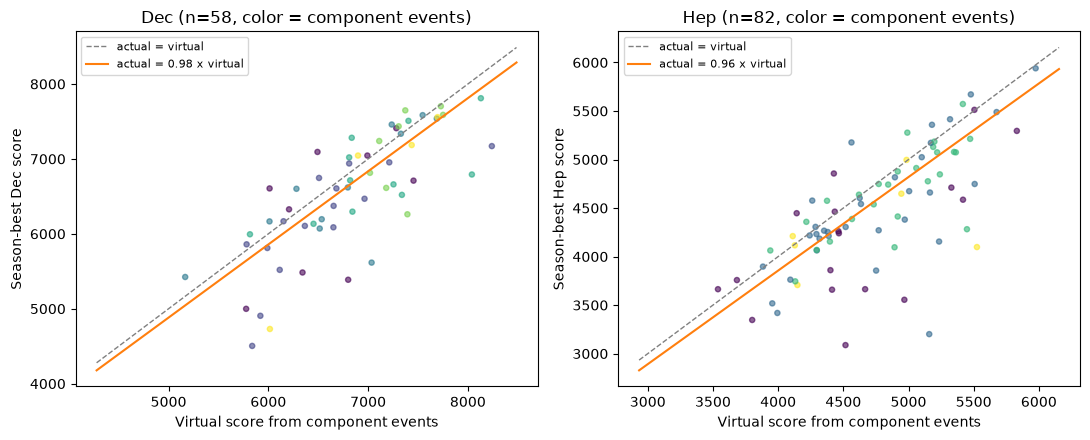

In [ ]:
both = vs[vs["season_multi"].notna() & (vs["n_events"] >= 4)].copy()
both["ratio"] = both["season_multi"] / both["virtual"]

rows = []
for m, grp in both.groupby("multi"):
    for k in [4, 5, 6, 7]:
        s = grp[grp["n_events"] >= k]
        if len(s) >= 5:
            rows.append(dict(multi=m, min_events=k, n=len(s), spearman=stats.spearmanr(s["virtual"], s["season_multi"])[0],
                             actual_over_virtual=s["ratio"].median(),
                             error_pct=100 * np.median(np.abs(np.log(s["season_multi"] / (s["virtual"] * s["ratio"].median()))))))
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (m, grp) in zip(axes, both.groupby("multi")):
    ax.scatter(grp["virtual"], grp["season_multi"], s=14, alpha=0.6, c=grp["n_events"], cmap="viridis")
    lim = [grp[["virtual", "season_multi"]].min().min() * 0.95, grp[["virtual", "season_multi"]].max().max() * 1.03]
    ax.plot(lim, lim, "--", color="gray", lw=1, label="actual = virtual")
    ax.plot(lim, np.array(lim) * grp["ratio"].median(), color="C1", lw=1.5, label=f"actual = {grp['ratio'].median():.2f} x virtual")
    ax.set_xlabel("Virtual score from component events"); ax.set_ylabel(f"Season-best {m} score")
    ax.set_title(f"{m} (n={len(grp)}, color = component events)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Does the virtual score predict the Big West score?
Errors are log ratios (≈ %): + means the athlete scored higher at Big West than predicted.

In [ ]:
ratio = both.groupby("multi")["ratio"].median()
bwm = me[me["status"] == "VALID"].copy()
bwm["virtual_adj"] = bwm["virtual"] * bwm["event"].map(ratio)
bwm["log_err_season"] = np.log(bwm["value"] / bwm["season_multi"])
bwm["log_err_virtual"] = np.log(bwm["value"] / bwm["virtual_adj"])
ok = bwm["n_events"] >= 4

def summarize(mask, col):
    e = bwm.loc[mask, col].dropna()
    return pd.Series({"n": len(e), "bias %": 100 * e.mean(), "median abs error %": 100 * e.abs().median()})

display(pd.DataFrame({
    "season multi score (has one)":           summarize(bwm["has_multi"], "log_err_season"),
    "virtual score, same athletes":           summarize(bwm["has_multi"] & ok, "log_err_virtual"),
    "virtual score, NO season multi score":   summarize(~bwm["has_multi"] & ok, "log_err_virtual"),
}).T.round(2))

,n,bias %,median abs error %
season multi score (has one),126.0,3.50,3.04
"virtual score, same athletes",115.0,1.98,4.16
"virtual score, NO season multi score",23.0,-1.36,2.91


### Can component events flag likely multi athletes?
Of athlete-seasons with marks in at least *k* component events, the share that also did a multi that season.

In [ ]:
flag = []
for m in TABLES:
    s = vs[vs["multi"] == m]
    for k in range(3, len(TABLES[m]) + 1):
        sub = s[s["n_events"] >= k]
        flag.append(dict(multi=m, min_component_events=k, athlete_seasons=len(sub),
                         did_a_multi=sub["season_multi"].notna().mean()))
display(pd.DataFrame(flag).round(2))

,multi,min_component_events,athlete_seasons,did_a_multi
0,Dec,3,113,0.54
1,Dec,4,76,0.76
2,Dec,5,64,0.77
3,Dec,6,41,0.83
4,Dec,7,28,0.82
5,Dec,8,17,0.71
6,Dec,9,6,0.67
7,Dec,10,0,NaN
8,Hep,3,164,0.56
9,Hep,4,115,0.71


**Summary**
- 3% of Big West multi entrants had no multi score that season, but most competed in  component events. 
- A virtual score (component season bests converted with the World Athletics tables and scaled to the full event) ranks athletes well (Spearman r = 0.80 for the decathlon, 0.70 for the heptathlon), with real scores about 2–4% below it.
- Large misses are almost always overestimates, because a no-height or foul-out in one event sinks a real multi. For entrants without a season multi score, the adjusted virtual score predicts the Big West score with a median error of about 3%, close to using a real season score.
- Multi athletes also score about 3.5% above their season-best multi at Big West, unlike every other event group. Athletes with marks in 4+ component events did a multi that season 71–76% of the time.

## 18. Team form
**Question:** do teammates over- or under-perform together at Big West (a shared team "good day" or "bad day")?

4,553 individual entries | robust SD of residual: 2.03%
Team effect SD: 0.31%  (athlete residual SD 2.85%)
Share of residual variance shared by teammates: 1.2%
Permutation p-value: 0.018  (share of shuffles with as much team clustering)


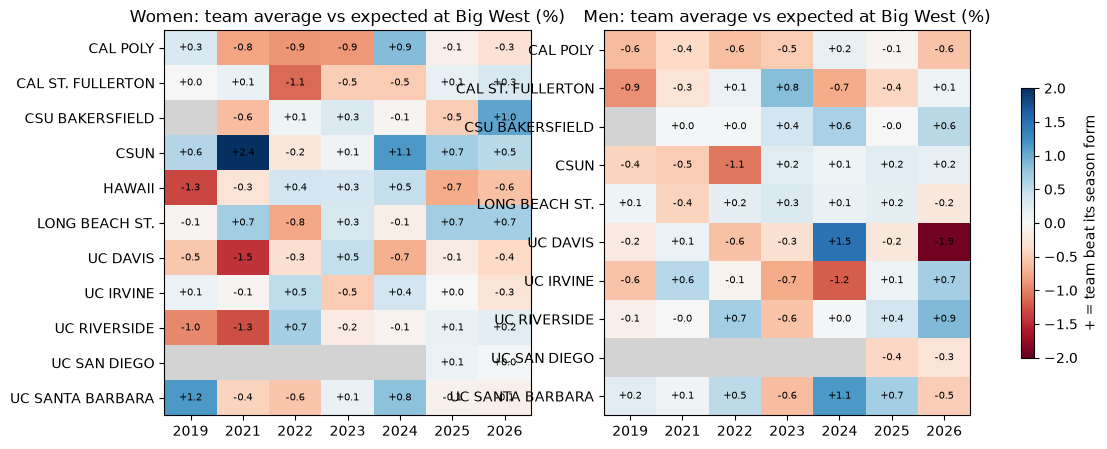

In [ ]:
# Individual Big West entrants with a valid mark and a season summary (same rows as section 6)
ind_g = gap[~gap["event"].isin(bm.RELAYS)].copy()
ind_g["gap_sb"] = ind_g["p"] - ind_g["best"]
ind_g["gap_mean"] = ind_g["p"] - ind_g["mean"]
# Residual: gap to season mean, minus that event's typical gap that year (removes conditions and event offsets)
ind_g["resid"] = ind_g["gap_mean"] - ind_g.groupby(["season", "gender", "event"])["gap_mean"].transform("median")
# Blowups (pull-ups, falls) would dominate variances, so clip at 4 robust SDs
mad_sd = stats.median_abs_deviation(ind_g["resid"], scale="normal")
ind_g["resid_c"] = ind_g["resid"].clip(-4 * mad_sd, 4 * mad_sd)
print(f"{len(ind_g):,} individual entries | robust SD of residual: {100 * mad_sd:.2f}%")

def between_team_var(df):
    """Variance of team-meet mean residuals, minus what pure noise would give for that team size."""
    g = df.groupby(["season", "gender", "team"])["resid_c"]
    means, sizes = g.mean(), g.size()
    noise = (df["resid_c"].var() / sizes).mean()
    return means.var() - noise

obs = between_team_var(ind_g)
rng = np.random.default_rng(0)
null = []
for _ in range(500):   # shuffle teams within each season and gender: no team effect by construction
    sh = ind_g.copy()
    sh["team"] = sh.groupby(["season", "gender"])["team"].transform(lambda t: rng.permutation(t.to_numpy()))
    null.append(between_team_var(sh))
null = np.array(null)
team_sd = np.sqrt(max(obs, 0))
print(f"Team effect SD: {100 * team_sd:.2f}%  (athlete residual SD {100 * ind_g['resid_c'].std():.2f}%)")
print(f"Share of residual variance shared by teammates: {max(obs, 0) / ind_g['resid_c'].var():.1%}")
print(f"Permutation p-value: {(null >= obs).mean():.3f}  (share of shuffles with as much team clustering)")

tm = (ind_g.groupby(["gender", "team", "season"])["resid_c"].agg(["mean", "size"])
      .query("size >= 5")["mean"].mul(100).unstack("season"))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, g in zip(axes, ["W", "M"]):
    d = tm.xs(g, level="gender")
    cmap = plt.get_cmap("RdBu").copy(); cmap.set_bad("lightgray")
    im = ax.imshow(np.ma.masked_invalid(d.to_numpy(dtype=float)), cmap=cmap, vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(d.shape[1]), d.columns); ax.set_yticks(range(d.shape[0]), d.index)
    for i in range(d.shape[0]):
        for j in range(d.shape[1]):
            if pd.notna(d.iat[i, j]):
                ax.text(j, i, f"{d.iat[i, j]:+.1f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{'Women' if g == 'W' else 'Men'}: team average vs expected at Big West (%)")
fig.colorbar(im, ax=axes, shrink=0.7, label="+ = team beat its season form")
plt.show()

**Summary**
- Teammates' Big West results are linked beyond chance (permutation p = 0.018), but the shared team effect is small: about 0.3% per team-meet against 2.9% for individual athletes (about 1% of the variation).
- Most team-years fall within ±1% of expected, the largest swings are about 2% (e.g. CSUN women 2021, UC Davis men 2026), and no team consistently beats or misses its form. A small shared team term would widen team-total ranges without changing expected points; it does not explain the 2026 women's misses.

## 19. Error vs number of marks
**Question:** are Big West results noisier for athletes with only a few regular-season marks?

,entries,robust_sd_pct,median_abs_pct,blowup_rate
n_bin,,,,
1,435,2.315,1.534,0.025
2,481,2.014,1.338,0.027
3-4,1208,1.800,1.212,0.020
5-7,1728,2.000,1.358,0.020
8+,701,2.316,1.568,0.024


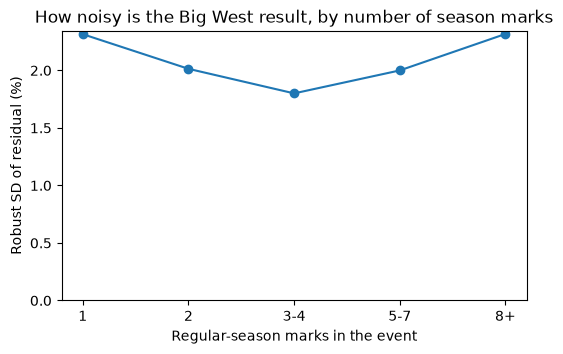

In [ ]:
ind_g["n_bin"] = pd.cut(ind_g["n"], [0, 1, 2, 4, 7, 100], labels=["1", "2", "3-4", "5-7", "8+"])
by_n = ind_g.groupby("n_bin", observed=True).agg(
    entries=("resid", "size"),
    robust_sd_pct=("resid", lambda r: 100 * stats.median_abs_deviation(r, scale="normal")),
    median_abs_pct=("resid", lambda r: 100 * r.abs().median()),
    blowup_rate=("resid", lambda r: (r < -4 * mad_sd).mean()))
display(by_n.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(by_n.index.astype(str), by_n["robust_sd_pct"], marker="o")
ax.set_xlabel("Regular-season marks in the event"); ax.set_ylabel("Robust SD of residual (%)")
ax.set_title("How noisy is the Big West result, by number of season marks"); ax.set_ylim(bottom=0)
plt.show()

**Summary**
- The number of marks barely affects how predictable an athlete is. The spread of Big West results stays between 1.8% and 2.3% across all groups.
- The blowup rate(rate that athlete performs far worse than the athlete’s season form would suggest) stays at 2.0–2.7% in every group, so the chance of a disaster is about the same however much data an athlete has.

## 20. Year-to-year change
**Question:** how much does an athlete's season best change from one season to the next in the same event?
`change_pct` is + for improvement. 2019→2021 spans two years (no 2020 season).

In [ ]:
sbs = summ[~summ["event"].isin(bm.RELAYS)][["season", "gender", "event", "athlete_id", "best", "group"]]
nxt = sbs.assign(season=sbs["season"].map({2019: 2021, 2021: 2022, 2022: 2023, 2023: 2024, 2024: 2025, 2025: 2026}))
yy = nxt.dropna(subset=["season"]).drop(columns="group").merge(sbs, on=["season", "gender", "event", "athlete_id"],
                                                               suffixes=("_prev", ""))
yy["change_pct"] = 100 * (yy["best"] - yy["best_prev"])
yy["pair"] = (yy["season"].astype(int) - np.where(yy["season"] == 2021, 2, 1)).astype(str) + "→" + yy["season"].astype(int).astype(str)
print(f"{len(yy):,} athlete-event pairs with season bests in consecutive seasons")
display(yy.groupby("group")["change_pct"].describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]].round(2))
display(yy.pivot_table(index="group", columns="pair", values="change_pct", aggfunc="median").round(2))

yy["level"] = pd.qcut(yy.groupby(["season", "gender", "event"])["best_prev"].rank(pct=True), 4,
                      labels=["bottom 25%", "25-50%", "50-75%", "top 25%"])
print("Median change by last season's level in the event")
display(yy.groupby("level", observed=True)["change_pct"].agg(["median", "size"]).round(2))

5,575 athlete-event pairs with season bests in consecutive seasons


,count,25%,50%,75%
group,,,,
distance,1849.0,-0.83,0.96,2.70
horizontal jump,474.0,-1.59,0.99,3.40
multi,86.0,1.84,5.50,10.58
sprint/hurdle,1834.0,-0.60,0.81,2.11
throw,958.0,-0.44,3.42,7.95
vertical jump,374.0,-1.44,1.23,3.85


pair,2019→2021,2021→2022,2022→2023,2023→2024,2024→2025,2025→2026
group,,,,,,
distance,0.66,1.68,1.08,0.54,1.19,0.70
horizontal jump,-0.65,0.77,2.05,0.80,1.69,0.35
multi,5.37,6.33,8.46,3.33,4.62,5.66
sprint/hurdle,-0.44,1.22,0.87,0.81,1.00,0.64
throw,3.52,4.57,2.55,2.99,3.77,3.07
vertical jump,2.75,1.08,1.57,0.86,1.21,1.02


Median change by last season's level in the event


,median,size
level,,
bottom 25%,2.45,1394
25-50%,1.32,1398
50-75%,0.92,1415
top 25%,0.27,1368


**Summary**
- Athletes usually improve from one season to the next, and how much depends on the event; sprints/distance/jumps are about 1% better; throws are 3.4% better, multi's are 5% better
- The spread is wide. About a quarter of athletes get worse. The middle half ranges from roughly −1% to +3% in most groups, and up to +8% in throws and +11% in multis. So last season’s mark is only a rough guide to this season.
-The pattern is stable across seasons. Every season pair shows similar gains. The exception is 2019→2021, where sprints and horizontal jumps got slightly worse (−0.4% and −0.7%). That pair spans two years, including the COVID disruption.
- Weaker athletes have more room to develop. Some of it is also regression to the mean: a low season best is partly bad luck.


## 21. How often the favourite wins
**Question:** how predictable are Big West events from season bests alone? Entrants are seeded by season best


In [ ]:
fav = bw[~bw["event"].isin(bm.RELAYS)][["season", "gender", "event", "athlete_id", "group", "place", "points", "status"]].copy()
fav = fav.merge(summ[["season", "gender", "event", "athlete_id", "best"]], on=["season", "gender", "event", "athlete_id"], how="left")
fav["seed"] = fav.groupby(["season", "gender", "event"])["best"].rank(ascending=False, method="first", na_option="bottom")
fav["place_n"] = pd.to_numeric(fav["place"], errors="coerce")
fav["scored"] = fav["points"] > 0

ev = []
for (s, g, e), grp in fav.groupby(["season", "gender", "event"]):
    top = grp.loc[grp["seed"] == 1]
    ok = grp.dropna(subset=["place_n"])
    ev.append(dict(group=grp["group"].iat[0], seed1_won=bool((top["place_n"] == 1).any()),
                   seed1_scored=bool(top["scored"].any()),
                   top8_seeds_scoring=grp.loc[grp["seed"] <= 8, "scored"].mean(),
                   rank_corr=stats.spearmanr(ok["seed"], ok["place_n"])[0] if len(ok) > 3 else np.nan))
ev = pd.DataFrame(ev)
display(ev.groupby("group")[["seed1_won", "seed1_scored", "top8_seeds_scoring", "rank_corr"]].mean().round(2)
        .assign(events=ev.groupby("group").size()))
print(f"Overall: top seed wins {ev['seed1_won'].mean():.0%} | top seed scores {ev['seed1_scored'].mean():.0%} | "
      f"top-8 seeds who score {ev['top8_seeds_scoring'].mean():.0%}")

,seed1_won,seed1_scored,top8_seeds_scoring,rank_corr,events
group,,,,,
distance,0.47,0.96,0.75,0.69,70
horizontal jump,0.46,0.89,0.77,0.72,28
multi,0.50,1.00,0.88,0.67,14
sprint/hurdle,0.49,1.00,0.80,0.81,70
throw,0.70,0.95,0.80,0.79,56
vertical jump,0.86,1.00,0.81,0.77,28


Overall: top seed wins 56% | top seed scores 97% | top-8 seeds who score 79%


**Summary**
- Season bests predict the order well, but not exactly. The athlete with the best season best wins 56% of the time and scores 97% of the time. Only 79% of the top 8 by season best score, so about 1–2 of the 8 scoring places per event go to athletes ranked outside the top 8.
- The most predictable events are vertical jumps, throws, and sprint/hurldes; the least preidtable are distance and horizontal jumps
- Multis look predictable (88% of top-8 seeds score), but there are very few entratnts so probablu useless

## 22. Late-season trend
**Question:** beyond the recency-weighted average the model uses, does an athlete's *direction* over the last six weeks
(improving or declining) predict how they do at Big West?


In [ ]:
TREND_DAYS = 42      # look at the last 6 weeks of each athlete's season
HALF_LIFE = 45       # same recency weighting as the model

season_end = valid.groupby("season")["date"].max()
v22 = valid[~valid["event"].isin(bm.RELAYS)].copy()
v22["days_before_end"] = (v22["season"].map(season_end) - v22["date"]).dt.days

def trend_row(x):
    w = 0.5 ** (x["days_before_end"] / HALF_LIFE)
    recent = x[x["days_before_end"] <= TREND_DAYS]
    slope = np.nan
    if len(recent) >= 3 and recent["date"].nunique() >= 3:
        days = -recent["days_before_end"].to_numpy(dtype=float)
        slope = np.polyfit(days, recent["p"].to_numpy(), 1)[0] * 30   # change in p per 30 days
    return pd.Series({"weighted_mean": np.average(x["p"], weights=w), "slope_30d": slope, "n_recent": len(recent)})

tr = v22.groupby(["season"] + KEYS).apply(trend_row, include_groups=False).reset_index()
t22 = bw_valid[~bw_valid["event"].isin(bm.RELAYS)].merge(tr, on=["season"] + KEYS)
t22 = t22.dropna(subset=["slope_30d"])
t22["resid"] = t22["p"] - t22["weighted_mean"]
t22["resid"] -= t22.groupby(["season", "gender", "event"])["resid"].transform("median")   # remove event/year offset
print(f"{len(t22):,} entrants with 3+ marks on 3+ dates in their last {TREND_DAYS} days")

t22["trend"] = pd.qcut(t22["slope_30d"], 3, labels=["declining", "flat", "improving"])
display((t22.groupby("trend", observed=True)
         .agg(entrants=("resid", "size"),
              slope_pct_per_30d=("slope_30d", lambda s: 100 * s.median()),
              resid_vs_weighted_mean_pct=("resid", lambda r: 100 * r.median())).round(2)))
rho, pval = stats.spearmanr(t22["slope_30d"], t22["resid"])
print(f"Spearman r(trend, Big West vs weighted mean) = {rho:.3f} (p = {pval:.3f})")
display((100 * t22.groupby(["group", "trend"], observed=True)["resid"].median()).unstack().round(2))

2,456 entrants with 3+ marks on 3+ dates in their last 42 days


,entrants,slope_pct_per_30d,resid_vs_weighted_mean_pct
trend,,,
declining,819,-2.16,-0.07
flat,818,0.93,0.00
improving,819,4.40,0.15


Spearman r(trend, Big West vs weighted mean) = 0.064 (p = 0.002)


trend,declining,flat,improving
group,,,
distance,-0.05,0.00,0.08
horizontal jump,-0.34,-0.01,0.44
sprint/hurdle,0.00,-0.03,0.22
throw,-0.18,0.06,0.06
vertical jump,0.00,0.15,-0.11


**Summary**
-  An athlete's direction over the last six weeks adds almost nothing beyond the recency-weighted average. Improving athletes beat their weighted average at Big West by only 0.15% and declining athletes fell short by 0.07% (Spearman r = 0.06), about a tenth of the typical 2% spread; even the largest effect, in horizontal jumps (±0.4%), is small. The model's recency weighting already captures recent form, so no trend term is needed.

## 23. Prelims vs finals
**Question:** in events with two rounds (100–1500 m and hurdles), do finalists run faster in the final, does the prelim
order carry into the final, and how often does a non-finalist's prelim mark beat a finalist's final mark?

In [ ]:
AUDIT_PATH = "../data/raw/bigwest_2019_2026_audit.csv"
ROUNDS_PATH = "../data/raw/bigwest_2019_2026_rounds.csv"   # audit file with a round column

aud = pd.read_csv(AUDIT_PATH)
aud["round"] = aud["event"].str.extract(r"(Preliminaries|Finals)$", expand=False)
aud = aud[aud["round"].notna()].copy()
aud["event"] = aud["event"].str.replace(r"\s+(Preliminaries|Finals)$", "", regex=True)
aud.to_csv(ROUNDS_PATH, index=False)

aud = bm.load_bigwest(ROUNDS_PATH, CFG)        # file path, as your version expects
aud = aud[aud["status"] == "VALID"]
aud["place_n"] = pd.to_numeric(aud["place"], errors="coerce")

pf = (aud.pivot_table(index=["season", "gender", "event", "athlete_id"], columns="round", values="p", aggfunc="max")
      .dropna(subset=["Preliminaries", "Finals"]))
pf["final_vs_prelim_pct"] = 100 * (pf["Finals"] - pf["Preliminaries"])
pf = pf.reset_index()
print(f"{len(pf):,} finalists with a valid mark in both rounds")
display(pf.groupby("event")["final_vs_prelim_pct"]
        .agg(median="median", improved=lambda x: (x > 0).mean(), n="size").round(2))

# Does prelim order predict final order?
fin = aud[aud["round"] == "Finals"][["season", "gender", "event", "athlete_id", "place_n"]]
pre = aud[aud["round"] == "Preliminaries"].copy()
pre["prelim_rank"] = pre.groupby(["season", "gender", "event"])["p"].rank(ascending=False, method="first")
pr = fin.merge(pre[["season", "gender", "event", "athlete_id", "prelim_rank"]], on=["season", "gender", "event", "athlete_id"])
corr = pr.groupby(["season", "gender", "event"]).apply(
    lambda g: stats.spearmanr(g["prelim_rank"], g["place_n"])[0] if len(g) > 3 else np.nan, include_groups=False)
print(f"Prelim rank vs final place, Spearman r (median over events): {corr.median():.2f}")
print(f"Fastest prelim qualifier wins the final: "
      f"{pr[pr['prelim_rank'] == 1].eval('place_n == 1').mean():.0%}")

# How often would a non-finalist's prelim mark have placed in the final?
fmarks = aud[aud["round"] == "Finals"].groupby(["season", "gender", "event"])["p"].apply(np.sort)
nonfin = pre[~pre.set_index(["season", "gender", "event", "athlete_id"]).index.isin(
             fin.set_index(["season", "gender", "event", "athlete_id"]).index)]
beats = [(row.p > fmarks.get((row.season, row.gender, row.event), np.array([np.inf]))).sum()
         for row in nonfin.itertuples()]
nonfin = nonfin.assign(finalists_beaten=beats)
print(f"Non-finalists whose prelim mark beats at least one finalist's FINAL mark: "
      f"{(nonfin['finalists_beaten'] > 0).mean():.1%} of {len(nonfin):,}")
display(nonfin.assign(beats_a_finalist=nonfin["finalists_beaten"] > 0).groupby("event")
        .agg(share=("beats_a_finalist", "mean"), non_finalists=("beats_a_finalist", "size"),
             avg_finalists_beaten=("finalists_beaten", "mean")).round(2))

830 finalists with a valid mark in both rounds


,median,improved,n
event,,,
100,-0.09,0.45,115
100H,0.47,0.69,54
110H,0.61,0.69,54
1500,0.55,0.61,153
200,0.13,0.55,112
400,0.22,0.56,115
400H,1.19,0.75,112
800,0.52,0.67,115


Prelim rank vs final place, Spearman r (median over events): 0.67
Fastest prelim qualifier wins the final: 50%
Non-finalists whose prelim mark beats at least one finalist's FINAL mark: 34.2% of 1,060


,share,non_finalists,avg_finalists_beaten
event,,,
100,0.43,222,0.69
100H,0.15,72,0.22
110H,0.13,47,0.28
1500,0.55,121,1.79
200,0.43,207,0.66
400,0.22,168,0.34
400H,0.27,79,0.38
800,0.24,144,0.40


**Summary**
- In two-round events, finals are usually faster than prelims , and the prelim order only partly carries over (Spearman r = 0.67; the fastest qualifier wins 50% of finals).
- A third of non-finalists ran a prelim faster than at least one finalist's final mark (55% in the 1500, 43% in the 100 and 200), yet they score nothing because only finalists can place 1–8. 

## 24. Weather
**Question:** do temperature, rain and humidity on the meet day change regular-season marks, and does

In [ ]:
import statsmodels.api as sm
mpsf = reg[reg["meet_name"].str.contains("MPSF", case=False, na=False)].groupby("season")["date"].max()
name, month = reg["meet_name"].fillna(""), reg["date"].dt.month
named_indoor = (name.str.contains(r"indoor|NCAA Division I Indoor|Arkansas Qualifier|BYU Cougar", case=False)
                | (name.str.contains("last chance", case=False) & month.between(1, 3)))
named_outdoor = name.str.contains(r"sunbird|rossi relays", case=False)
reg["venue"] = np.where(named_indoor | ((reg["date"] <= reg["season"].map(mpsf)) & ~named_outdoor), "indoor", "outdoor")


In [ ]:
o = reg[(reg["venue"] == "outdoor") & (reg["status"] == "VALID") & reg["temp"].notna()
        & ~reg["event"].isin(bm.MULTIS)].copy()
o["group"] = o["event"].map(event_group)
o["days"] = (o["season"].map(o.groupby("season")["date"].max()) - o["date"]).dt.days
o["rain"] = (o["precip_in"] >= 0.05).astype(float)
key = ["season", "gender", "event", "athlete_id"]
o = o[o.groupby(key)["p"].transform("size") >= 3].copy()
for c in ["p", "temp", "rain", "humidity_max", "days"]:
    o[c + "_d"] = o[c] - o.groupby(key)[c].transform("mean")      # within athlete-event-season
o = o[o["p_d"].abs() < 4 * stats.median_abs_deviation(o["p_d"], scale="normal")]   # drop blowups
o["meet_day"] = o["meet_name"] + "|" + o["date"].astype(str)
print(f"{len(o):,} outdoor marks from {o['meet_day'].nunique()} meet days")

terms = {"temp_d": "per +10°F", "rain_d": "rain day (≥0.05 in)", "humidity_max_d": "per +10% humidity",
         "days_d": "per 30 days earlier"}
rows = []
for g, d in list(o.groupby("group")) + [("ALL", o)]:
    X = pd.DataFrame({"temp_d": d["temp_d"] / 10, "rain_d": d["rain_d"],
                      "humidity_max_d": d["humidity_max_d"] / 10, "days_d": d["days_d"] / 30})
    fit = sm.OLS(100 * d["p_d"], X).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["meet_day"])[0]})
    for t, lab in terms.items():
        rows.append(dict(group=g, term=lab, effect=fit.params[t], p=fit.pvalues[t]))
wx = pd.DataFrame(rows)
wx["cell"] = wx["effect"].map("{:+.2f}".format) + np.where(wx["p"] < 0.05, " *", "")
print("Effect on the mark (%); * = p < 0.05")
display(wx.pivot(index="group", columns="term", values="cell")[list(terms.values())])

# Is the temperature effect non-linear? (season timing removed)
o["temp_bin"] = pd.cut(o["temp"], [0, 60, 65, 70, 75, 80, 85, 120],
                       labels=["<60", "60-65", "65-70", "70-75", "75-80", "80-85", "85+"])
slope = np.polyfit(o["days_d"], o["p_d"], 1)[0]
print("Within-athlete mark by temperature (%, season timing removed)")
display((100 * (o["p_d"] - slope * o["days_d"])).groupby([o["group"], o["temp_bin"]], observed=True)
        .mean().unstack().round(2))

34,820 outdoor marks from 311 meet days
Effect on the mark (%); * = p < 0.05


term,per +10°F,rain day (≥0.05 in),per +10% humidity,per 30 days earlier
group,,,,
ALL,+0.18 *,-0.20 *,+0.08 *,-0.63 *
distance,-0.03,-0.30 *,+0.10 *,-0.62 *
horizontal jump,+0.10,-0.33,-0.04,-0.56 *
relay,+0.39 *,-0.27,+0.22 *,-0.87 *
sprint/hurdle,+0.18 *,-0.11,-0.01,-0.57 *
throw,+0.22 *,-0.11,+0.14 *,-0.64 *
vertical jump,+0.17 *,-0.26,+0.11 *,-0.41 *


Within-athlete mark by temperature (%, season timing removed)


temp_bin,<60,60-65,65-70,70-75,75-80,80-85,85+
group,,,,,,,
distance,-0.03,-0.05,0.12,0.07,0.04,0.14,-0.37
horizontal jump,-0.01,-0.05,0.02,0.30,-0.09,0.53,0.42
relay,-0.12,0.19,0.05,0.27,0.50,0.56,0.37
sprint/hurdle,-0.07,0.03,-0.03,0.04,0.14,0.17,0.35
throw,0.02,0.06,0.29,0.34,0.15,0.74,0.20
vertical jump,0.02,0.06,-0.03,0.21,-0.01,0.13,0.10


In [ ]:
coef = wx[wx["group"] != "ALL"].pivot(index="group", columns="term", values="effect") / 100
v = reg[(reg["status"] == "VALID") & ~reg["event"].isin(bm.MULTIS)].copy()
v["group"] = v["event"].map(event_group)
c = coef.reindex(v["group"]).to_numpy()
cols = list(coef.columns)
adj = (c[:, cols.index("per +10°F")] * (v["temp"] - 70) / 10
       + c[:, cols.index("rain day (≥0.05 in)")] * (v["precip_in"] >= 0.05)
       + c[:, cols.index("per +10% humidity")] * (v["humidity_max"] - 90) / 10)
outdoor = (v["venue"] == "outdoor") & v["temp"].notna()
v["p_adj"] = np.where(outdoor, v["p"] - adj.fillna(0), v["p"])
v["w"] = 0.5 ** ((v["season"].map(v.groupby("season")["date"].max()) - v["date"]).dt.days / 45)

def summaries(col):
    g = v.assign(wp=v["w"] * v[col]).groupby(key)
    return pd.DataFrame({"weighted mean": g["wp"].sum() / g["w"].sum(), "best": g[col].max(), "mean": g[col].mean()})

act = bw[(bw["status"] == "VALID") & ~bw["event"].isin(bm.RELAYS | bm.MULTIS)].set_index(key)["p"].rename("act")
out = {}
for label, s in [("unadjusted", summaries("p")), ("weather-adjusted", summaries("p_adj"))]:
    j = s.join(act, how="inner")
    out[label] = {c: 100 * (j["act"] - j[c] - (j["act"] - j[c]).groupby(level=["gender", "event"]).transform("mean"))
                  .abs().mean() for c in ["weighted mean", "best", "mean"]}
print(f"Bias-corrected MAE (%) predicting the Big West mark, {len(j):,} athlete-events")
display(pd.DataFrame(out).T.round(3))
shift = 100 * (summaries("p_adj")["weighted mean"] - summaries("p")["weighted mean"])
print(f"How much the adjustment moves an athlete's weighted mean: median {shift.median():+.2f}%, "
      f"90% within {shift.quantile(0.05):+.2f}% to {shift.quantile(0.95):+.2f}%")

**Summary**
- Meet-day weather has small but measurable effects on regular-season marks
- When the weather is warmer athletes do slightly better(+0.2%) overall: bust specifically relayes, sprints, throws and vertical jumps, temperature does not seem to effect distance events thoug
- Rains  hurts athletes: across all events rain slightly hurts athletes(-0.2%) but specifically in distance and jumps it hurts more(-0.3%)
- Humidity has a tiny effecr of about (+0.1%)
- As heat increases explosive events improve steadily with heat 
- As soon as temperature rises above 85 distance athletes appear to perform worse 

## What the EDA means for the model

### Changes to make
| Change | Evidence | Section |
|---|---|---|
| **Simulate prelims and finals separately** in the 100–1500 m and hurdles | A third of non-finalists ran a prelim faster than at least one finalist's final (55% in the 1500, 43% in the 100/200), but only finalists can score. A single simulated mark per athlete gives some of these points to non-finalists. | 23 |
| **Impute missing multi scores from component events** (4+ events, World Athletics tables) | 23% of multi entrants had no season multi score; the virtual score ranks athletes well (r = 0.80 Dec, 0.70 Hep) and predicts the Big West score within about 3%. | 17 |
| **Add year-to-year improvement to the prior-season fallback**, by event group and level | Returning athletes improve about 1% (sprints, distance, jumps), 3.4% (throws) and 5.5% (multis); the weakest improve most (+2.5% vs +0.3% for the top quarter). | 20 |
| **Add a small shared team-form term** (SD ≈ 0.3%) | Teammates' Big West results are linked beyond chance (p = 0.018), though the effect is small (about 1% of the variation). It widens team-total ranges without changing expected points. | 18 |
| **Compare field versions**: actual Big West entrants vs everyone with regular-season marks | About one capable athlete per event per gender is not entered each year, so entering everyone will overrate deep teams. | 5, 12 |
| Recency-weighted average (45-day half-life) plus a per-event offset | Season mean and best predict equally well after removing their typical shift; the last 6 weeks' trend adds almost nothing (±0.1%). | 6, 22 |
| Blowups treated as failures, not slow marks | The middle of the gap distribution is normal, but tails are very heavy; about 2% of results are blowups, whatever the number of marks. | 6, 19 |
| Championship failure rates from Big West results, combined with athlete history | Season failure rate predicts Big West failure (2.5% → 12%), but sprints/hurdles and vertical jumps fail at different rates at the championship. | 11 |
| Converted marks weighted below direct marks; indoor marks converted only for events not held outdoors | Indoor 200/400/800 and field events are used directly. Strong conversions to keep: 60→100, 60H→100H/110H, Mile→1500, 3000→5000, WT→HT, Pent→Hep (r ≈ 0.74–0.90). Use with caution: 600→400/800 and 3000→3000S (r ≈ 0.62–0.81). Drop or replace: M Hep→Dec (r = 0.60, n = 17; use the virtual multi score), 300, 1000, 2000 and 2000S conversions (≤ 22 athletes); LJ↔TJ should not be converted. | 8, 9, 17 |
| Indoor marks used directly | The indoor–outdoor gap in sprints is no bigger than in field events, so it reflects in-season improvement, not the venue. | 9 |
| Wind-aided marks kept | They predict as well as legal marks (1.90% vs 1.93% error). | 10 |
| Moderate shrinkage of each athlete's spread (`k_spread`) | Prediction noise barely changes with the number of marks (1.8–2.3%). | 19 |
| Shared day-form term across an athlete's events; no doubling penalty | Results across events are weakly linked (r ≈ 0.12); athletes in 2+ events do not underperform. | 13 |
| Relays treated as a single competitor | Relays are the most predictable events (spread 1.1–1.5%). | 14 |
| 2019 included | Its performance levels match 2021–2022. | 4 |

### Limitations to report
- **Known starters:** fields come from the results, which list only athletes who started. DNS removes an athlete from the meet, so the results closely match declared entries, but late scratches are invisible (6 DNS in 5,257 entries). (12)
- **Rising performance levels:** 2025–2026 marks are 1–3% better than earlier years, so marks from different years are not directly comparable. (4)
- **Weakest coverage:** the 10000 (only 31–44% ran one during the season), multis and the 5000 rely on conversions. (2)
- **HJ/PV ties:** 35% of vertical-jump athletes end in tied places with split points, which a continuous simulation never produces. This affects per-athlete point distributions, not expected points. (15)
- **Ceiling on predictability:** the top seed wins 56% of events and 21% of top-8 seeds fail to score; distance and horizontal jumps are the least predictable. (21)